# Kia and Hyundai Vehicle Theft Early Warning Analysis
Author: Violetta Kalinicheva  
Date: October 28, 2026  
Modified by: Violetta Kalinicheva

## 1. Audience, question, and decision
For municipal public-safety analysts: what do consistently reported monthly counts show about the escalation of Kia and Hyundai thefts between 2019 and 2022? This retrospective descriptive story informs how to monitor emerging brand-specific patterns. It is not a validated forecasting model, a causal social-media study, or a current theft-risk estimate.

I keep four sources separate: Milwaukee city-months, a multicity extract, a broader VICE location-month workbook, and all-vehicle agency-year counts. Their jurisdictions can overlap, and their reporting periods differ. Adding them would double count events.

In [1]:
# I load separate raw sources and check each grain before making comparisons.
source('analysis.R')
d <- load_and_audit()
print(d$audit[c('milwaukee_rows','multicity_rows','multicity_cities','agency_rows',
               'vice_long_rows','vice_locations','vice_missing_both_counts',
               'vice_zero_totals','vice_percentage_mismatches','vice_percentage_mismatch_locations')])

$milwaukee_rows
[1] 48

$multicity_rows
[1] 552

$multicity_cities
[1] 13

$agency_rows
[1] 556

$vice_long_rows
[1] 3150

$vice_locations
[1] 70

$vice_missing_both_counts
[1] 69

$vice_zero_totals
[1] 1

$vice_percentage_mismatches
[1] 42

$vice_percentage_mismatch_locations
$vice_percentage_mismatch_locations$`Los Angeles, CA`
[1] 42




## Data fitness and cleaning
The files contain 48 Milwaukee months, 552 multicity rows across 13 cities, 556 agency rows, and a 47-row by 211-column workbook. Reshaping 70 three-column location blocks produces 3,150 unique location-month rows. Sixty-nine lack both counts. One observed total is zero, so its share is undefined rather than zero or infinite. Forty-two Los Angeles source percentages disagree with their displayed counts. I retain source percentages and use a separate recalculated count-based share.

Monthly share checks allow the source's three-decimal rounding. Dash/blank tokens in counts remain missing. No missing event count is filled. I do not add agency rows together because geographic coverage may overlap and agency reporting changes can affect comparisons.

In [2]:
# I require complete reporting in the identical four-year city comparison.
s <- summarize_thefts(d)
print(s$coverage)
print(s$milwaukee_annual)
print(s$multicity_annual)
print(s$metrics[c('complete_cities','complete_city_months','complete_cities_growth_pct',
                 'chicago_contribution_pct','vice_complete_2022_locations')])

            city year months
1        Atlanta 2019     12
2      Baltimore 2019     12
3        Chicago 2019     12
4         Dayton 2019     12
5     Louisville 2019     12
6          Omaha 2019     12
7       Portland 2019     12
8      Rochester 2019     12
9        Seattle 2019     12
10       Atlanta 2020     12
11     Baltimore 2020     12
12       Buffalo 2020     12
13       Chicago 2020     12
14     Cleveland 2020     12
15        Dayton 2020     12
16    Louisville 2020     12
17         Omaha 2020     12
18      Portland 2020     12
19     Rochester 2020     12
20    Saint Paul 2020     12
21       Seattle 2020     12
22       Atlanta 2021     12
23     Baltimore 2021     12
24       Buffalo 2021     12
25       Chicago 2021     12
26     Cleveland 2021     12
27        Dayton 2021     12
28    Louisville 2021     12
29         Omaha 2021     12
30      Portland 2021     12
31     Rochester 2021     12
32    Saint Paul 2021     12
33       Seattle 2021     12
34       Atlan

  year countKiaHyundaiThefts countOtherThefts total share_pct
1 2019                   207             3281  3488  5.934633
2 2020                   895             3649  4544 19.696303
3 2021                  6971             3507 10478 66.529872
4 2022                  4679             3377  8056 58.080933


  year countKiaHyundaiThefts countOtherThefts total share_pct
1 2019                  1866            33598 35464  5.261674
2 2020                  2000            35492 37492  5.334471
3 2021                  2315            39131 41446  5.585581
4 2022                 12592            43607 56199 22.406093


$complete_cities
[1] "Atlanta"    "Baltimore"  "Chicago"    "Dayton"     "Louisville"
[6] "Omaha"      "Portland"   "Rochester"  "Seattle"   

$complete_city_months
[1] 432

$complete_cities_growth_pct
[1] 443.9309

$chicago_contribution_pct
[1] 58.87905

$vice_complete_2022_locations
[1] 64



## 3. Visual story
The sequence starts with Milwaukee, expands to a fixed nine-city comparison, identifies contributions, checks a broader workbook, and ends with separate all-vehicle context. Each chart states its population and period.

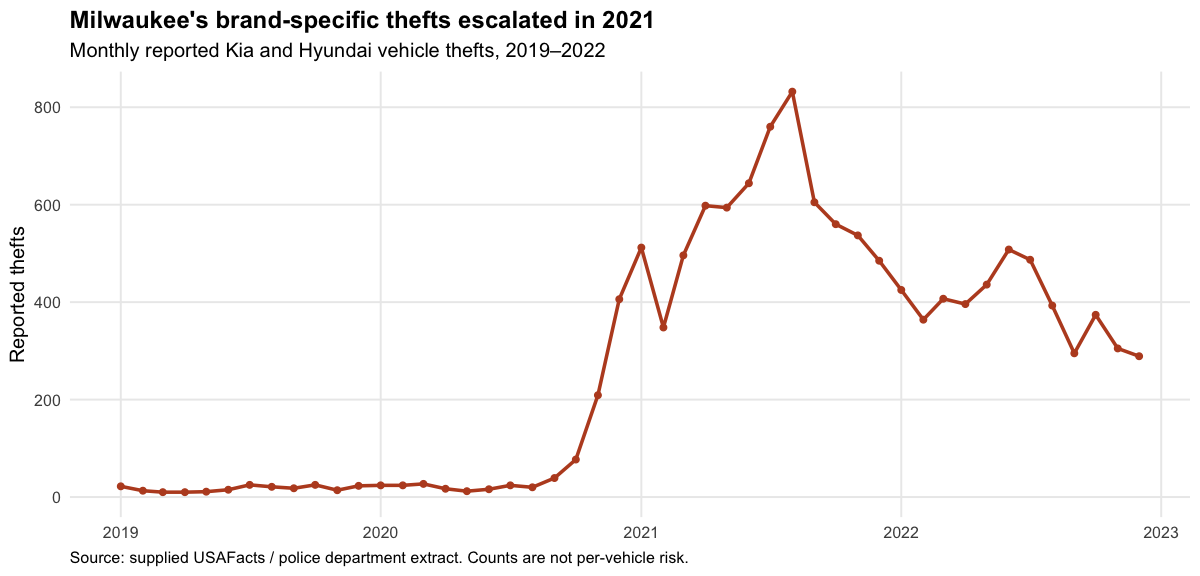

In [3]:
# I establish Milwaukee's escalation before expanding to other reporting populations.
options(repr.plot.width = 10, repr.plot.height = 4.8)
print(plot_story(d, s, 1))

### Visualization 1 interpretation
Milwaukee recorded 207 Kia and Hyundai thefts in 2019, 5.93% of all reported vehicle thefts, and 6,971 in 2021, 66.53%. Those are proportions of reported stolen vehicles, not the probability that a registered Kia or Hyundai was stolen. Brand-specific exposure denominators are unavailable.

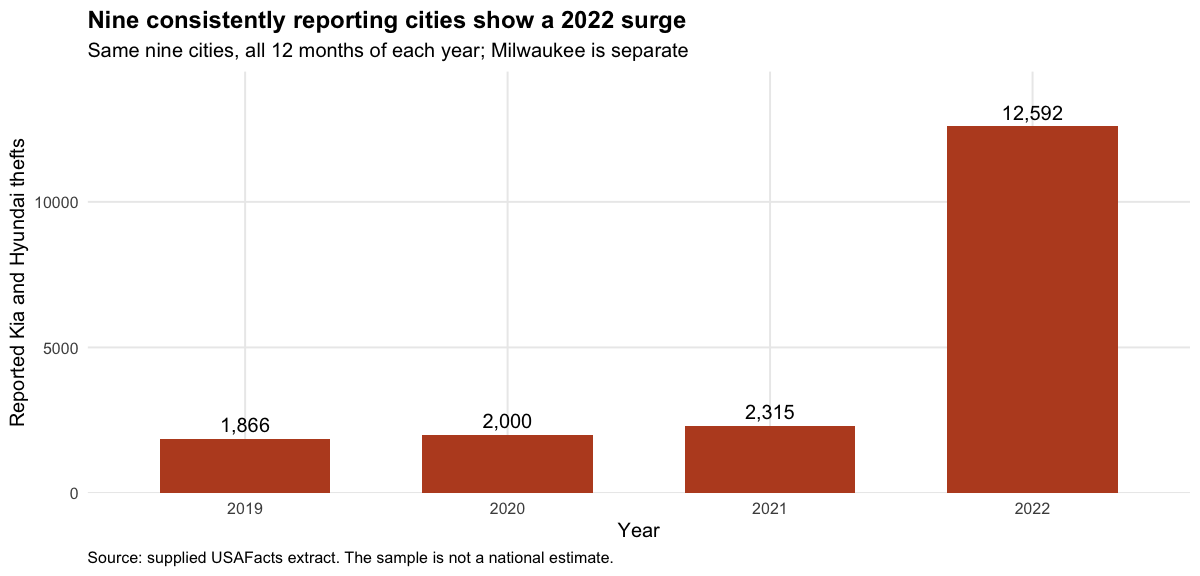

In [4]:
# I hold the city set and number of reporting months fixed.
print(plot_story(d, s, 2))

### Visualization 2 interpretation
Nine cities have all 48 monthly observations from 2019 through 2022. Within that fixed set, Kia and Hyundai thefts rise from 2,315 in 2021 to 12,592 in 2022, a 443.93% increase. All nine record an increase. Four partially observed cities are excluded only from this comparison and remain in the coverage audit. Milwaukee is not part of these nine cities.

        city countKiaHyundaiThefts_2021 countKiaHyundaiThefts_2022 increase
3    Chicago                        750                       6801     6051
7   Portland                        214                       1315     1101
9    Seattle                        183                        818      635
4     Dayton                         39                        666      627
5 Louisville                        265                        751      486
2  Baltimore                        391                        807      416
6      Omaha                        146                        557      411
1    Atlanta                        181                        586      405
8  Rochester                        146                        291      145


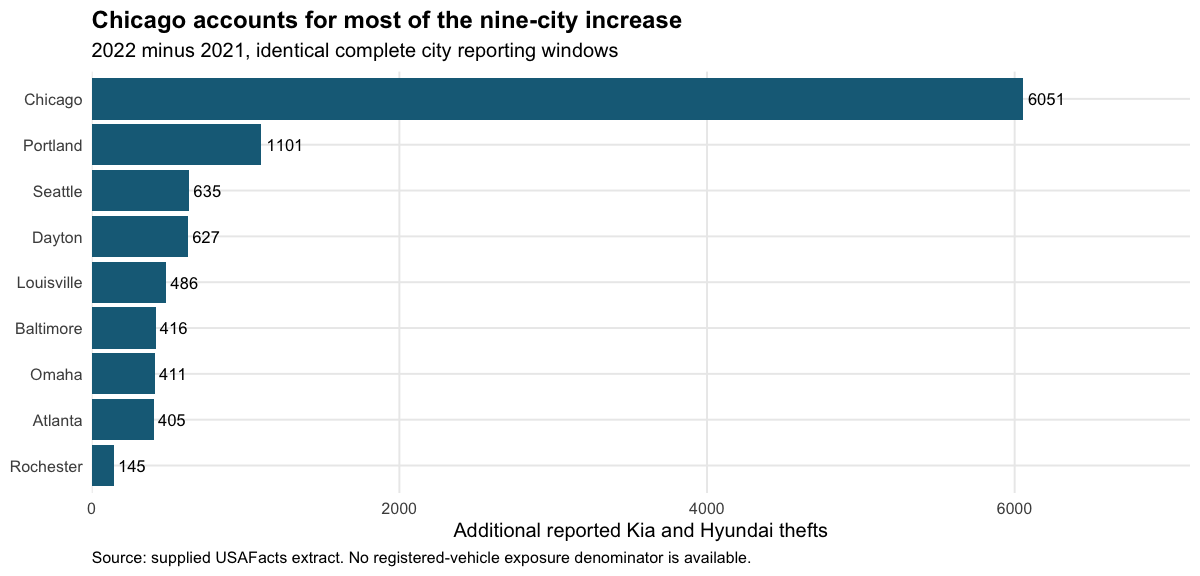

In [5]:
# I reconcile every city's contribution to the combined change.
print(s$changes[order(-s$changes$increase), ])
print(plot_story(d, s, 3))

### Visualization 3 interpretation
Chicago contributes 58.88% of the combined nine-city increase. The count comparison identifies where reported volume changed most, not which city's residents faced the highest per-vehicle risk. Registered vehicle populations, model-year mix, and local reporting practices could change that ranking.

             location kia_hyundai total share_pct
32      Milwaukee, WI        4621  8043  57.45369
14         Cincinatti         801  2309  34.69034
33    Minneapolis, MN        2490  7623  32.66431
17             Denver        4568 14117  32.35815
12            Chicago        6460 21450  30.11655
53        San Antonio        1904  6981  27.27403
10        Buffalo, NY         411  1713  23.99299
46     Providence, RI          69   304  22.69737
5             Atlanta         747  3311  22.56116
59 St. Petersburg, FL         179   840  21.30952
27    Los Angeles, CA        4984 24722  20.16018
38          Omaha, NE         655  3706  17.67404


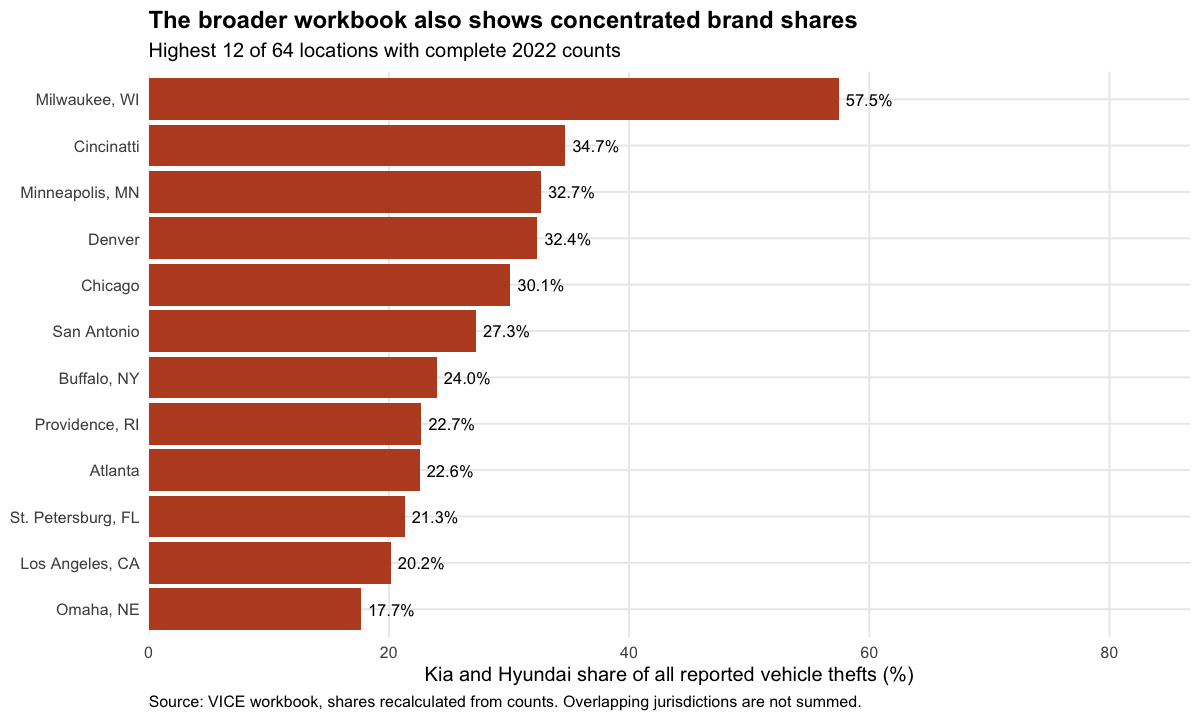

In [6]:
# I use only complete 12-month 2022 locations in the separate VICE workbook.
options(repr.plot.height = 6)
print(head(s$vice_annual, 12))
print(plot_story(d, s, 4))

### Visualization 4 interpretation
Sixty-four VICE locations have both counts for all 12 months of 2022. Twenty-seven have brand shares at least 10%, and eleven exceed 20%. This supports a broader descriptive concern, but locations may overlap each other or the multicity extract. Their totals are not added together or treated as a national probability sample.

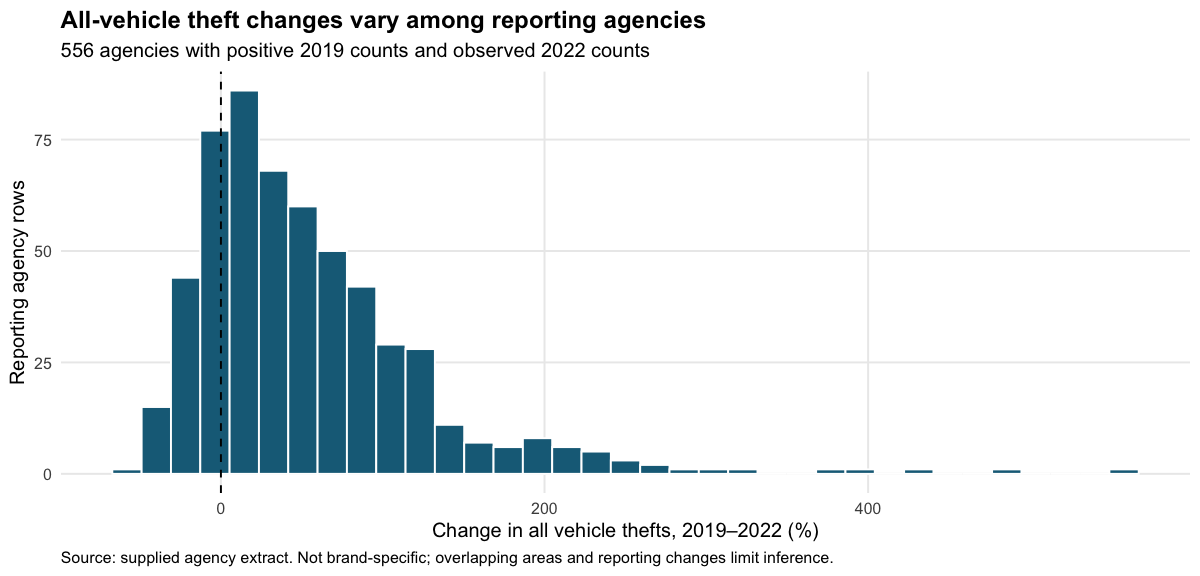

In [7]:
# I keep all-vehicle agency context separate from the brand-specific narrative.
options(repr.plot.height = 4.8)
print(plot_story(d, s, 5))

### Visualization 5 interpretation
Among 556 agency rows with positive 2019 counts and observed 2022 counts, 444 report an increase in all-vehicle thefts. The median agency change is 38.80%. This is an unweighted agency distribution, not a national growth rate and not an attribution to Kia or Hyundai.

## 4. Conclusion, action, and limitations
The historical data support a monitoring proposal: maintain monthly brand-specific counts and reporting-completeness checks, review accelerating patterns, and coordinate locally appropriate prevention outreach. No numeric alert threshold is validated here; a prospective evaluation with registered-vehicle exposure, comparable reports, and independent test periods is required before deployment. Official prevention guidance and eligibility should be checked at the source rather than inferred from 2019–2022 records.

The design uses orange for brand-specific counts, blue for context, direct labels, and zero-based bars. Descriptive timing cannot establish that social media caused thefts or quantify the effect of security updates. Neither ethnicity nor personal characteristics are inferred from geographic records. Raw files are excluded from the release because redistribution permission for all supplied extracts has not been established.

## References
- USAFacts. [Car thefts are rising](https://usafacts.org/articles/car-thefts/), May 26, 2023. Compiler documentation checked October 28, 2026.
- Motherboard / VICE. [Publisher workbook export](https://docs.google.com/spreadsheets/d/1-6614t_Ata5k7oESrm-HAdF1uOe8aPGRaQECl44GYeE/export?format=xlsx). Retrieved October 28, 2026. The entire Data sheet matched the earlier supplied workbook, and the full notebook was rerun on downloaded inputs.
- NHTSA. [Hyundai and Kia anti-theft campaign](https://www.nhtsa.gov/press-releases/hyundai-kia-campaign-prevent-vehicle-theft), February 14, 2023. Official source checked October 28, 2026.
- See data/README.md for the four supplied extracts and their exact acquisition URLs.

In [8]:
# I record the actual metrics, source hashes, and R versions after successful execution.
save_validation(s$metrics)
print(R.version.string)
print(sapply(required_packages, function(p) as.character(packageVersion(p))))
cat('Analysis completed; validation.json records the actual run.\n')

[1] "R version 4.5.2 (2025-10-31)"


  readxl jsonlite   digest  ggplot2 
 "1.4.5"  "2.0.0" "0.6.39"  "4.0.1" 


Analysis completed; validation.json records the actual run.
